# BÀI 2: PHÂN TÍCH CHI PHÍ BẢO HIỂM Y TẾ
**Nguồn dữ liệu:** [Medical Cost Personal Datasets — Kaggle](https://www.kaggle.com/datasets/mirichoi0218/insurance/data)

Cần có file insurance.csv sẵn trong máy tính. Nếu chưa có thì tải bằng đường link trên.

## 1. Kiểm tra dữ liệu trùng lặp, giá trị thiếu và kiểu dữ liệu

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_csv(file_name)

print('Kích thước:', df.shape)
display(df.head())
print('\nKiểu dữ liệu:')
print(df.dtypes)
print('\nGiá trị thiếu:')
print(df.isna().sum())
print('\nSố dòng trùng lặp:', df.duplicated().sum())

Saving insurance.csv to insurance.csv
Kích thước: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520



Kiểu dữ liệu:
age           int64
sex          object
bmi         float64
children      int64
smoker       object
region       object
charges     float64
dtype: object

Giá trị thiếu:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

Số dòng trùng lặp: 1

Thống kê mô tả:


,age,sex,bmi,children,smoker,region,charges
count,1338.000000,1338,1338.000000,1338.000000,1338,1338,1338.000000
unique,NaN,2,NaN,NaN,2,4,NaN
top,NaN,male,NaN,NaN,no,southeast,NaN
freq,NaN,676,NaN,NaN,1064,364,NaN
mean,39.207025,NaN,30.663397,1.094918,NaN,NaN,13270.422265
std,14.049960,NaN,6.098187,1.205493,NaN,NaN,12110.011237
min,18.000000,NaN,15.960000,0.000000,NaN,NaN,1121.873900
25%,27.000000,NaN,26.296250,0.000000,NaN,NaN,4740.287150
50%,39.000000,NaN,30.400000,1.000000,NaN,NaN,9382.033000
75%,51.000000,NaN,34.693750,2.000000,NaN,NaN,16639.912515


In [2]:
# Xóa dòng trùng và xử lý giá trị thiếu

df = df.drop_duplicates().copy()
for col in df.columns:
    if df[col].isna().any():
        if pd.api.types.is_numeric_dtype(df[col]):
            df[col] = df[col].fillna(df[col].median())
        else:
            mode = df[col].mode()
            if not mode.empty:
                df[col] = df[col].fillna(mode[0])
# Báo kết quả
print('Kích thước sau xử lý:', df.shape)
print('Giá trị thiếu còn lại:', df.isna().sum().sum())
print('Dòng trùng còn lại:', df.duplicated().sum())

Kích thước sau xử lý: (1337, 7)
Giá trị thiếu còn lại: 0
Dòng trùng còn lại: 0


## 2. So sánh chi phí theo tuổi, giới tính, khu vực và tình trạng hút thuốc

In [3]:
# Chia tuổi thành các nhóm để so sánh chi phí
bins = [17, 29, 39, 49, 59, 120]
labels = ['18–29', '30–39', '40–49', '50–59', '60+']
df['age_group'] = pd.cut(df['age'], bins=bins, labels=labels)

print('Chi phí theo nhóm tuổi:')
display(df.groupby('age_group', observed=False)['charges'].agg(['count', 'mean', 'median']))

for col in ['sex', 'region', 'smoker']:
    print(f'Chi phí theo {col}:')
    display(df.groupby(col)['charges'].agg(['count', 'mean', 'median']).round(2))

Chi phí theo nhóm tuổi:


,count,mean,median
age_group,,,
18–29,416,9200.619154,3220.371575
30–39,257,11738.784117,6082.405000
40–49,279,14399.203564,8606.217400
50–59,271,16495.232665,11729.679500
60+,114,21248.021885,14255.400500


Chi phí theo sex:


,count,mean,median
sex,,,
female,662,12569.58,9412.96
male,675,13975.00,9377.90


Chi phí theo region:


,count,mean,median
region,,,
northeast,324,13406.38,10057.65
northwest,324,12450.84,8976.98
southeast,364,14735.41,9294.13
southwest,325,12346.94,8798.59


Chi phí theo smoker:


,count,mean,median
smoker,,,
no,1063,8440.66,7345.73
yes,274,32050.23,34456.35


## 3. Tổng hợp bằng groupby(), agg() và pivot_table()

In [4]:
# groupby() và agg()
summary = df.groupby(['smoker', 'sex']).agg(
    so_luong=('charges', 'count'),
    chi_phi_trung_binh=('charges', 'mean'),
    chi_phi_trung_vi=('charges', 'median')
).round(2)
display(summary)

# pivot_table()
pivot = pd.pivot_table(
    df, index='region', columns='smoker', values='charges',
    aggfunc='mean'
).round(2)
print('Chi phí trung bình theo khu vực và tình trạng hút thuốc:')
display(pivot)

so_luong  chi_phi_trung_binh  chi_phi_trung_vi
smoker sex                                                   
no     female       547             8762.30           7639.42
       male         516             8099.70           6986.10
yes    female       115            30679.00          28950.47
       male         159            33042.01          36085.22

Chi phí trung bình theo khu vực và tình trạng hút thuốc:


smoker,no,yes
region,,
northeast,9165.53,29673.54
northwest,8582.47,30192.00
southeast,8032.22,34845.00
southwest,8019.28,32269.06


## 4. Dùng NumPy tính phân vị và phát hiện giá trị chi phí bất thường

In [5]:
charges = df['charges'].to_numpy()
q1, median, q3 = np.percentile(charges, [25, 50, 75])
iqr = q3 - q1
lower = q1 - 1.5 * iqr #Này là quy tắc tính ngoại lai. Vượt quá 1.5 iqr auto ngoại lai
upper = q3 + 1.5 * iqr

outliers = df[(df['charges'] < lower) | (df['charges'] > upper)]
print(f'Q1: {q1:.2f}')
print(f'Trung vị: {median:.2f}')
print(f'Q3: {q3:.2f}')
print(f'Ngưỡng dưới: {lower:.2f}')
print(f'Ngưỡng trên: {upper:.2f}')
print('Số giá trị chi phí bất thường:', len(outliers))
display(outliers[['age', 'sex', 'smoker', 'region', 'charges']].head())

Q1: 4746.34
Trung vị: 9386.16
Q3: 16657.72
Ngưỡng dưới: -13120.72
Ngưỡng trên: 34524.78
Số giá trị chi phí bất thường: 139


,age,sex,smoker,region,charges
14,27,male,yes,southeast,39611.7577
19,30,male,yes,southwest,36837.4670
23,34,female,yes,northeast,37701.8768
29,31,male,yes,southwest,38711.0000
30,22,male,yes,southwest,35585.5760


## 5. Biểu đồ scatterplot, histogram, boxplot và heatmap tương quan

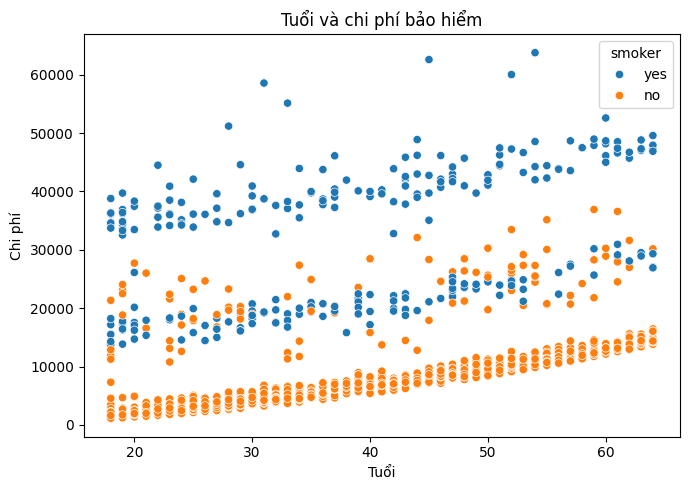

In [6]:
# Scatterplot: tuổi và chi phí, phân biệt tình trạng hút thuốc
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='age', y='charges', hue='smoker')
plt.title('Tuổi và chi phí bảo hiểm')
plt.xlabel('Tuổi')
plt.ylabel('Chi phí')
plt.tight_layout()
plt.show()

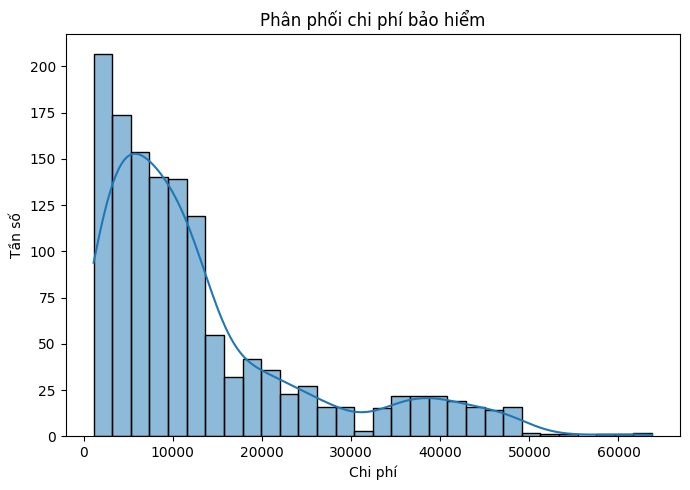

In [7]:
# Histogram: phân phối chi phí
plt.figure(figsize=(7, 5))
sns.histplot(data=df, x='charges', bins=30, kde=True)
plt.title('Phân phối chi phí bảo hiểm')
plt.xlabel('Chi phí')
plt.ylabel('Tần số')
plt.tight_layout()
plt.show()

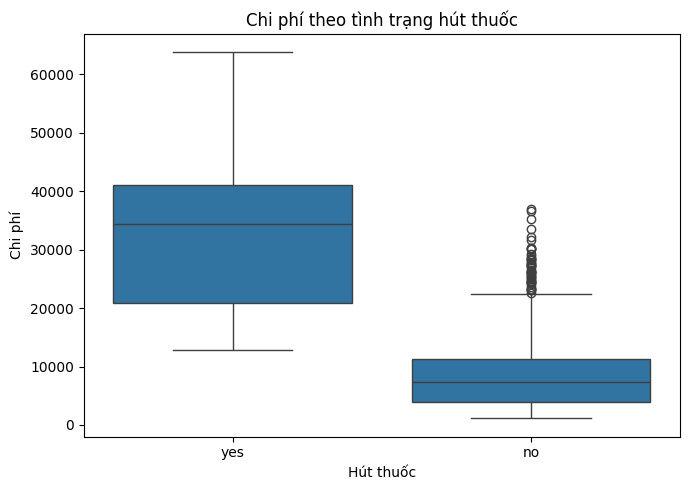

In [8]:
# Boxplot: chi phí theo tình trạng hút thuốc
plt.figure(figsize=(7, 5))
sns.boxplot(data=df, x='smoker', y='charges')
plt.title('Chi phí theo tình trạng hút thuốc')
plt.xlabel('Hút thuốc')
plt.ylabel('Chi phí')
plt.tight_layout()
plt.show()

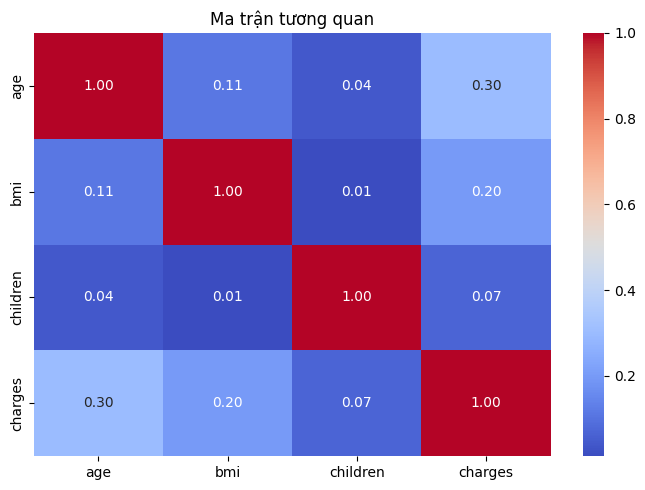

In [9]:
# Heatmap: tương quan giữa các biến số
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(7, 5))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Ma trận tương quan')
plt.tight_layout()
plt.show()